# 1. Khám phá và tiền xử lí dữ liệu

#Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

## 1.1: Load Datasets

In [2]:
import pandas as pd
data_path = "data/train.csv"
df = pd.read_csv(data_path)

In [3]:
df = df.drop(columns='id')

## 1.2: EDA

In [4]:
df.columns

Index(['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   amount_usd                    699960 non-null  float64
 1   hours_since_last_txn          699960 non-null  float64
 2   txn_count_last_24h            699960 non-null  int64  
 3   distance_from_home_km         699960 non-null  float64
 4   card_age_months               699960 non-null  int64  
 5   customer_age                  699960 non-null  int64  
 6   account_balance_usd           699960 non-null  float64
 7   cvv_retry_count               699960 non-null  int64  
 8   velocity_score                699960 non-null  float64
 9   time_of_day_hour              699960 non-null  int64  
 10  day_of_week                   699960 non-null  int64  
 11  merchant_risk_score           699960 non-null  float64
 12  prior_disputes                699960 non-null  int64  


In [6]:
df.isna().sum()

amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

Nhận xét: dữ liệu đầy đủ không xuất hiện các giá trị Nan nên không cần xử lí Nan

In [7]:
values = df['is_fraud'].value_counts()
values

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64

In [8]:
percent_class_0 = values[0]/len(df)
percent_class_1 = 1 - percent_class_0
print(f"%class_0: {round(percent_class_0*100, 2)}%")
print(f"%class_1: {round(percent_class_1*100, 2)}%")

%class_0: 98.33%
%class_1: 1.67%


Nhận xét: dữ liệu bị mất cân bằng nghiêm trọng với đa số là nhãn 0 chiếm tới 98.33% còn nhãn 1 chỉ có 1.67%. Do đó cần có biện pháp xử lí phù hợp như điều chỉnh trọng số lớp hoặc lấy mẫu lại trên tập huấn luyện. Khi đánh giá mô hình, không nên chỉ dựa vào chỉ số accuracy, mà cần xét đến precision, recall, F1-score vaf ROC-AUC để đánh giá khả năng phát hiện gian lận của mô hình.

In [9]:
X = df.drop(columns='is_fraud')
y = df['is_fraud']

#Tách dữ liệu các theo các loại

In [10]:
X_object = X.select_dtypes(exclude=["number", "bool"])
X_object.head()

,merchant_category,card_type,auth_method,channel,device_type
0,Groceries,Mastercard,OTP,POS,iPhone
1,Online Retail,Visa,PIN,In-App,Android Phone
2,Utilities,Visa,OTP,Online,Tablet
3,Groceries,Mastercard,3D Secure,POS,Android Phone
4,Electronics,Visa,3D Secure,Online,Windows PC


In [11]:
X_bool = X.select_dtypes(include=['bool'])
X_bool.head()

,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,True,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False


In [12]:
object_cols = X_object.columns
bool_cols = X_bool.columns
X_numerical = X.drop(columns=object_cols.to_list() + bool_cols.to_list())
X_numerical.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0


#Kiểm tra giá trị ngoại lệ của dữ liệu numerical

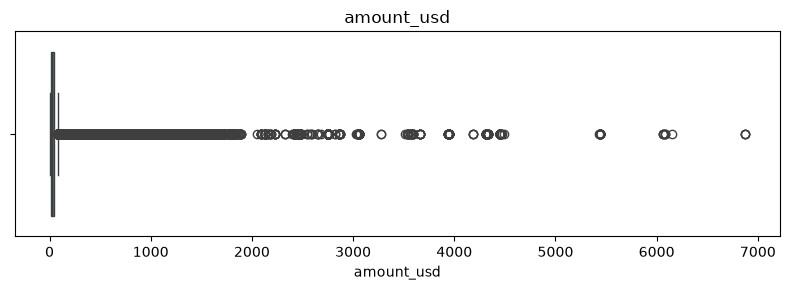

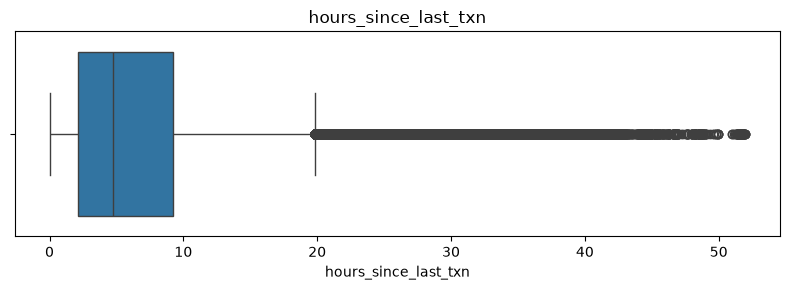

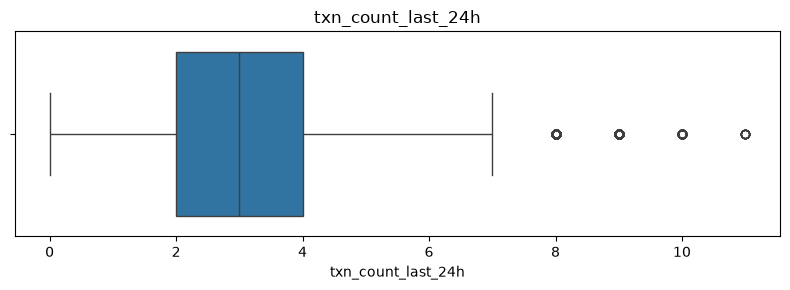

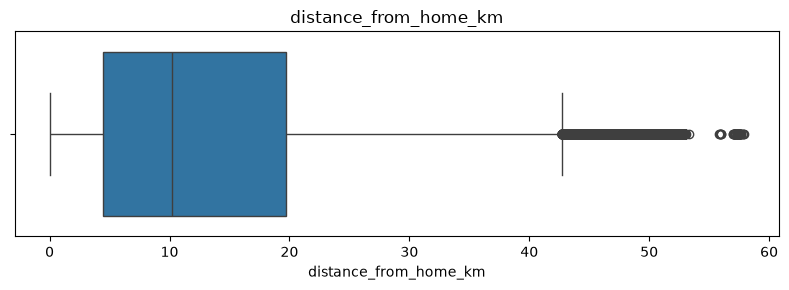

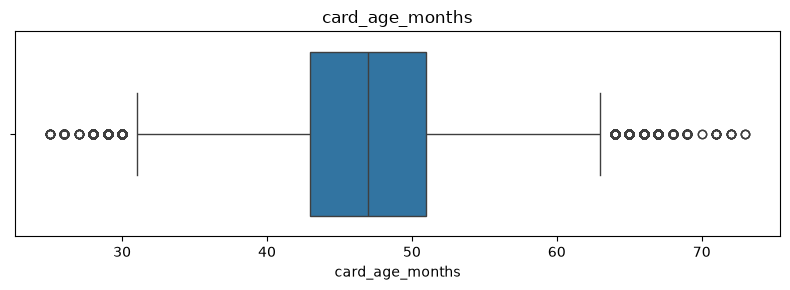

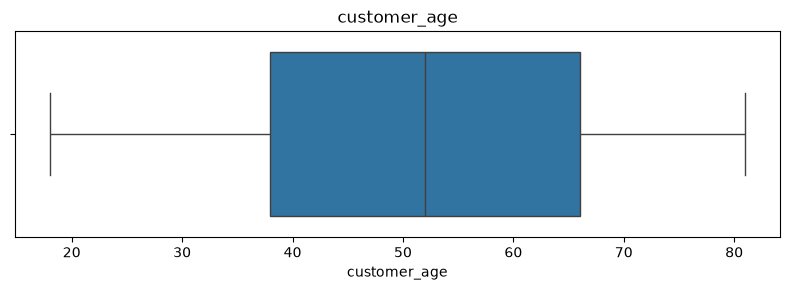

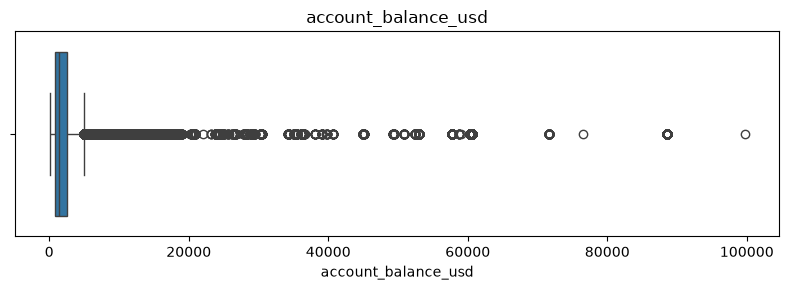

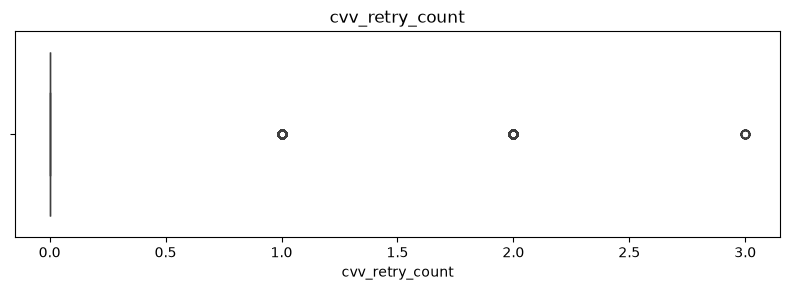

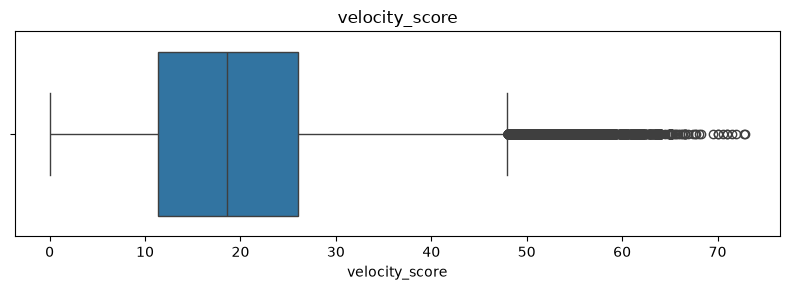

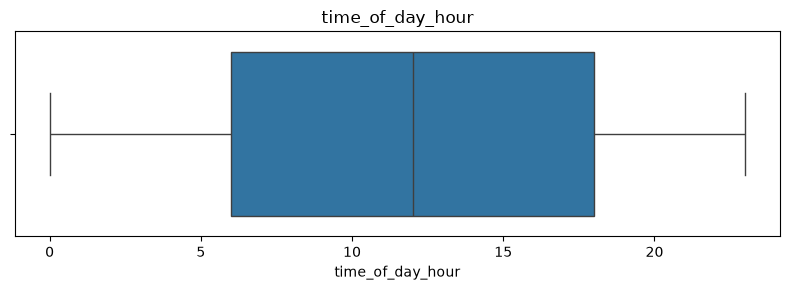

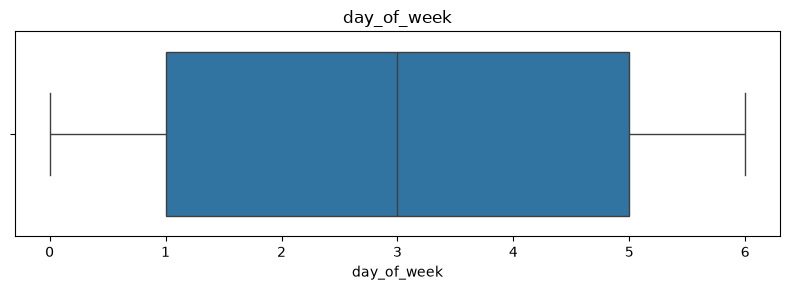

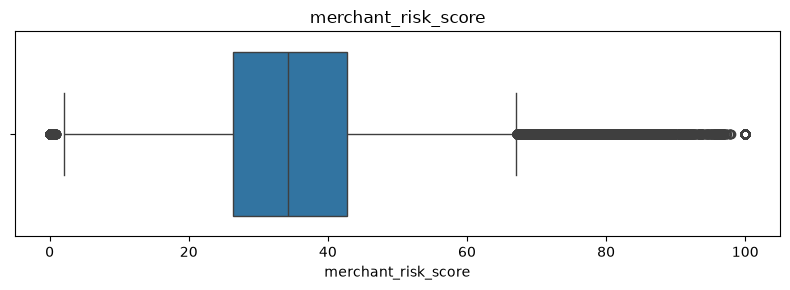

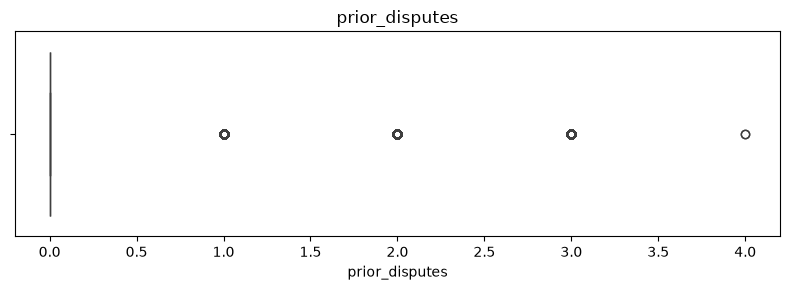

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in X_numerical.columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=X_numerical[col])
    plt.title(col)
    plt.tight_layout()
    plt.show()

Nhận xét: 

#Kiểm tra tương quan tuyến tính giữa các đặc trưng dạng numerical và nhãn

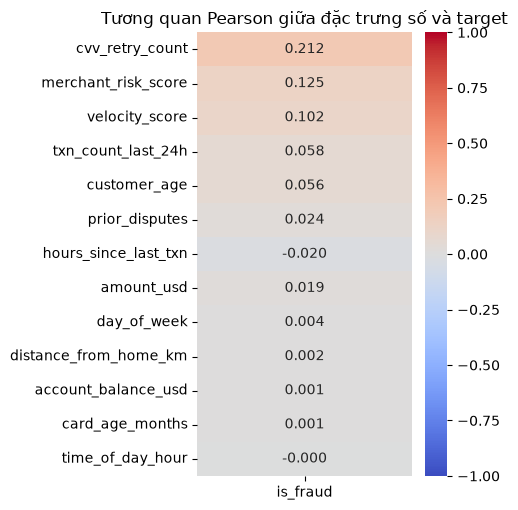

In [14]:

target_col = 'is_fraud'
numeric_cols = X_numerical.columns
corr_target = (
    df[list(numeric_cols) + [target_col]]
    .corr(method="pearson")[[target_col]]
    .drop(index=target_col)
)

corr_target = corr_target.loc[
    corr_target[target_col].abs().sort_values(ascending=False).index
]

plt.figure(figsize=(5, max(4, len(numeric_cols) * 0.4)))
sns.heatmap(
    corr_target,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Tương quan Pearson giữa đặc trưng số và target")
plt.tight_layout()
plt.show()

#Kiểm tra tương quan tuyến tính giữa các đặc trưng dạng numerical với nhau

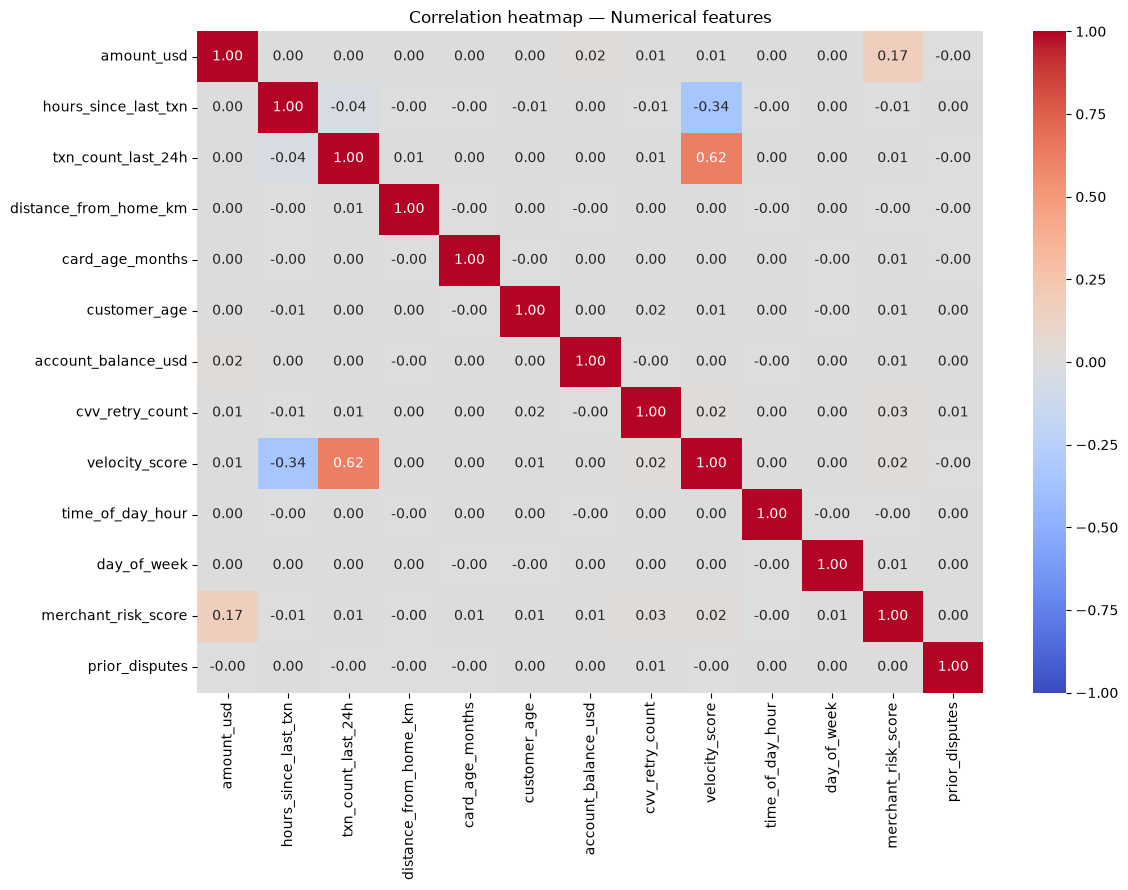

In [15]:

corr_matrix = X_numerical.corr(method="pearson")

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlation heatmap — Numerical features")
plt.tight_layout()
plt.show()

#Nhận xét: Các đặc trưng dạng số có hệ số tương quan tuyến tính với nhãn khá thấp, khoảng từ −0,02 đến 0,2. Điều này cho thấy từng đặc trưng riêng lẻ có mối liên hệ tuyến tính yếu với nhãn, nhưng chưa đủ để kết luận khả năng dự đoán khi kết hợp các đặc trưng. Vì vậy, nên sử dụng Logistic Regression làm mô hình cơ sở và thử nghiệm thêm các mô hình phi tuyến như Decision Tree, Random Forest để khai thác các quan hệ phi tuyến và tương tác giữa các đặc trưng. Việc lựa chọn mô hình cần dựa trên kết quả validation với các chỉ số phù hợp cho dữ liệu mất cân bằng như precision, recall, F1-score.

#Kiểm tra tỉ lệ gian lận trong từng nhóm categorical vaf bool

In [16]:
categorical_cols = X_object.columns.tolist() + X_bool.columns.tolist()
summaries = []
for col in categorical_cols:
    summary = (
        df.groupby(col)["is_fraud"]
        .agg(sample_count="size", fraud_count="sum", fraud_rate="mean")
        .sort_values("fraud_rate", ascending=False)
    )
    summary["fraud_rate"] *= 100
    summaries.append((col, summary))

    print(f"\n--- {col} (fraud_rate: %) ---")
    print(summary)


--- merchant_category (fraud_rate: %) ---
                   sample_count  fraud_count  fraud_rate
merchant_category                                       
Gift Cards                 9456        690.0    7.296954
Crypto Exchange            5285        345.0    6.527909
Gaming                    23784       1311.0    5.512109
Electronics               48693       1501.0    3.082579
Streaming                 47196       1061.0    2.248072
Travel                    28715        534.0    1.859655
Utilities                 42027        581.0    1.382445
Healthcare                35889        462.0    1.287303
Fuel                      59880        741.0    1.237475
Restaurants              101360       1159.0    1.143449
Groceries                142578       1585.0    1.111672
Online Retail            155097       1719.0    1.108339

--- card_type (fraud_rate: %) ---
            sample_count  fraud_count  fraud_rate
card_type                                        
Amex               45797

C:\Users\Long\AppData\Local\Temp\ipykernel_13180\3959435655.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=9)


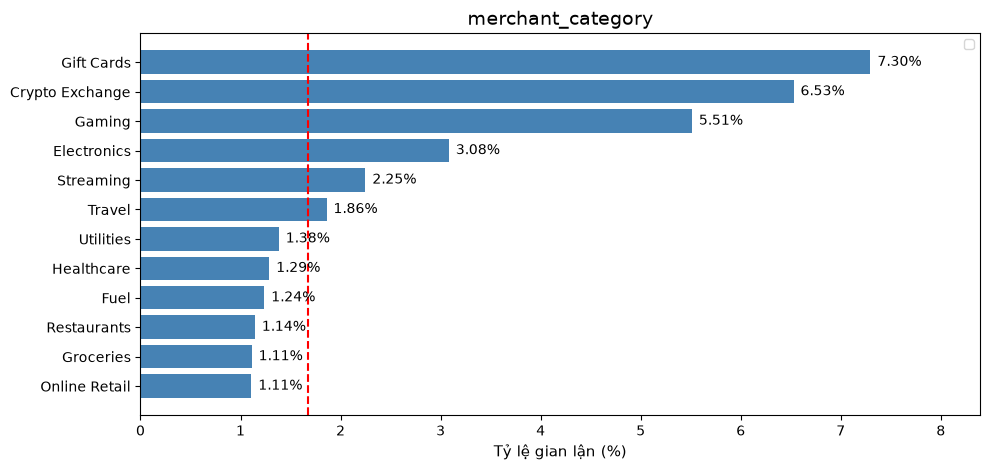

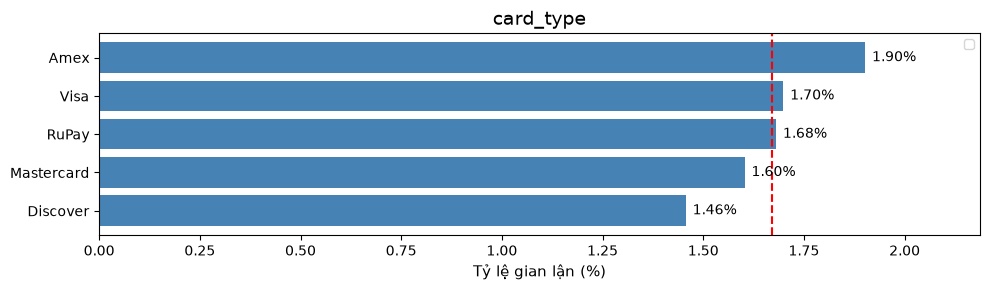

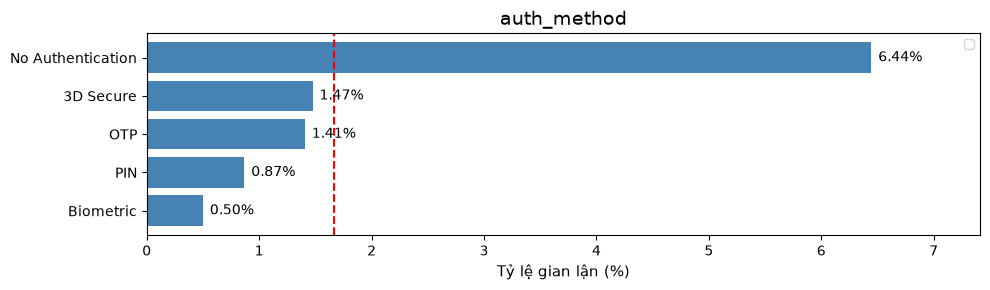

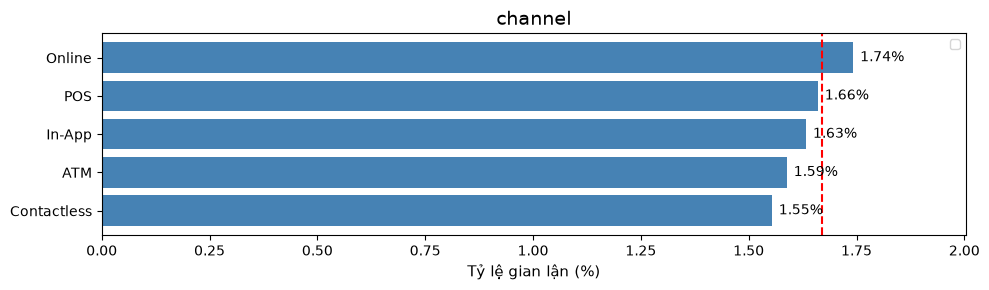

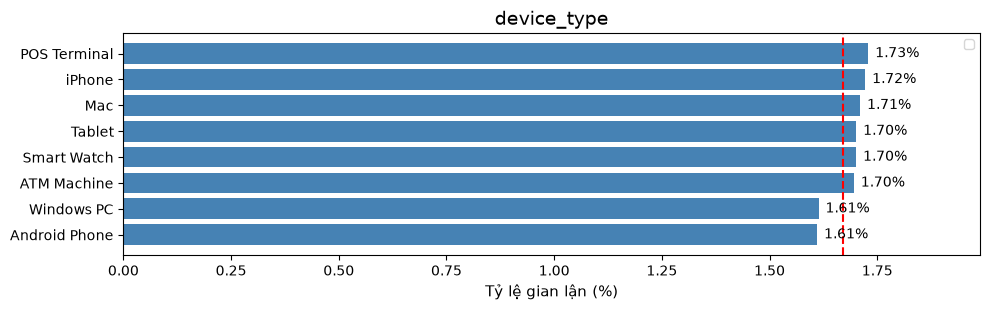

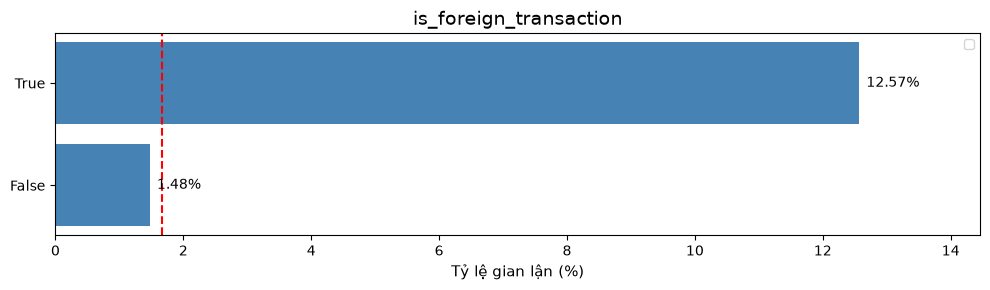

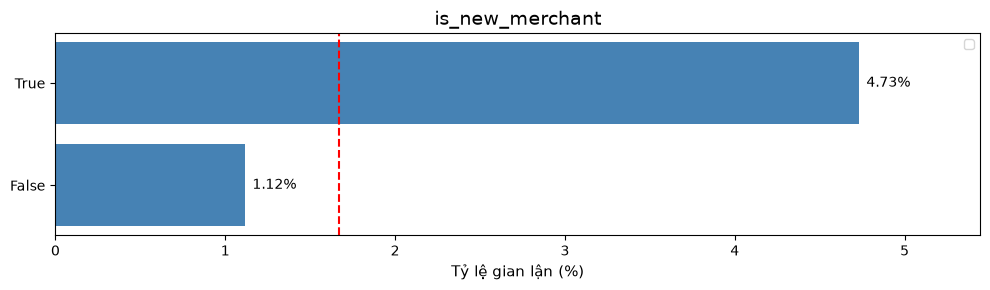

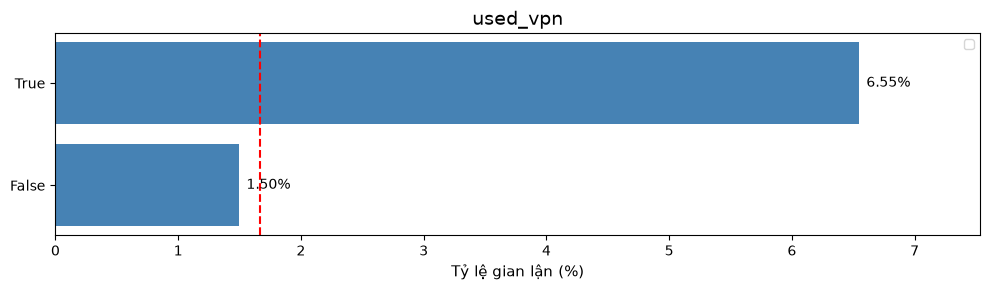

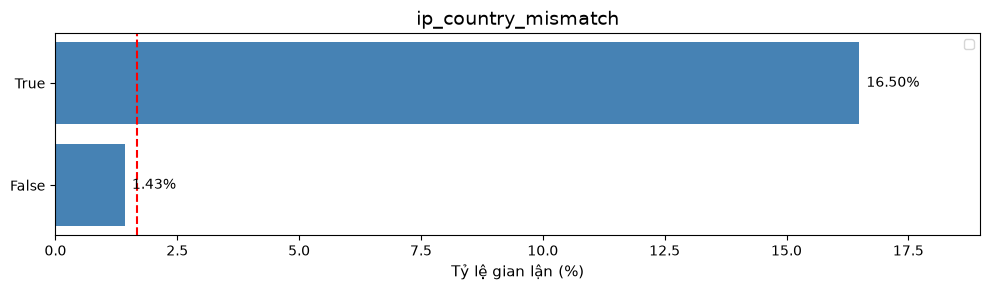

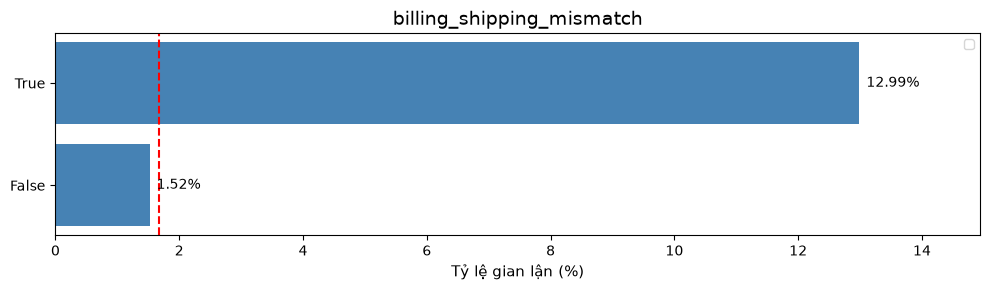

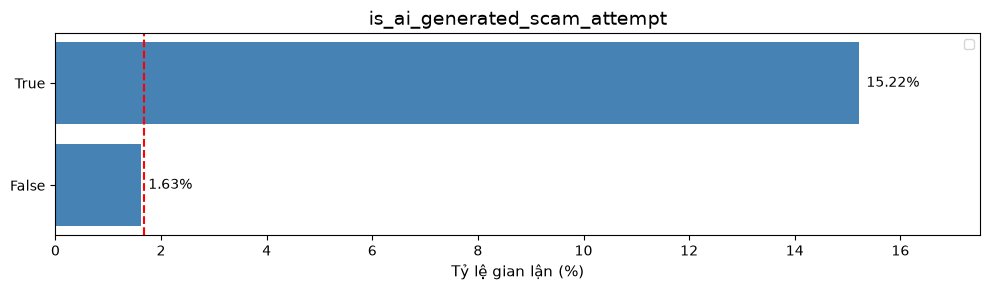

In [17]:
overall_rate = percent_class_1*100  #1.67%

for col, summary in summaries:
    fig, ax = plt.subplots(figsize=(10, max(3, len(summary) * 0.4)))

    bars = ax.barh(
        summary.index.astype(str),
        summary["fraud_rate"],
        color="steelblue",
    )
    ax.invert_yaxis()
    ax.bar_label(bars, fmt="%.2f%%", padding=5, fontsize=10)
    ax.axvline(
        overall_rate, color="red", linestyle="--"
    )

    ax.set_title(col, fontsize=14)
    ax.set_xlabel("Tỷ lệ gian lận (%)", fontsize=11)
    ax.tick_params(labelsize=10)
    ax.margins(x=0.15)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

Nhận xét: với đặc trưng dạng categorical tỉ lệ gian lận khác biệt rõ rệt giữa các nhóm thuộc merchant_category và auth_method, cho thấy 2 đăc trưng này có thể có ích cho việc phát hiện giao dịch gian lận. Ngược lại, tỉ lệ gian lận giữa các nhóm của card_type, channel va device_type ít có biến động giữa các lớp nên khả năng phân biệt khi xuất hiện riêng lẻ có thể khó. Với dữ liệu dạng bool các đặc trưng đều có sự biến động lớn giữa 2 lớp True và False. Đặc biệt các đặc trưng như ip_country_mismatch, is_foreign_transaction và is_ai_generated_scam_attempt có sự chênh lệch khá lớn về tỉ lệ gian lận của True so với False. Do đó các đặc trưng dạng bool có thể có ích trong việc hỗ trợ phát hiện gian lận, cần kết hợp các phương pháp kiểm định để làm rõ hơn mức độ liên hệ với nhãn.

## 1.4: Tiền xử lí dữ liệu

#Loại bỏ các đặc trưng categorical tốt hơn


In [18]:
# X_object = X_object.drop(columns=['card_type', 'channel', 'device_type'])
X_object

,merchant_category,card_type,auth_method,channel,device_type
0,Groceries,Mastercard,OTP,POS,iPhone
1,Online Retail,Visa,PIN,In-App,Android Phone
2,Utilities,Visa,OTP,Online,Tablet
3,Groceries,Mastercard,3D Secure,POS,Android Phone
4,Electronics,Visa,3D Secure,Online,Windows PC
...,...,...,...,...,...
699955,Travel,Mastercard,3D Secure,POS,Windows PC
699956,Restaurants,Mastercard,No Authentication,Online,iPhone
699957,Online Retail,Mastercard,Biometric,Online,Android Phone
699958,Groceries,Mastercard,PIN,ATM,Windows PC


In [19]:
X_features = pd.concat([X_numerical, X_object, X_bool], axis=1)
X_features.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,...,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,...,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,...,Visa,OTP,Online,Tablet,False,False,True,False,False,False
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,...,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,...,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False


#Chia train test

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y.astype(int), test_size=0.2, random_state=42, stratify=y
)

#Mã hóa dữ liệu dạng categorical và bool

In [21]:
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, OrdinalEncoder
from sklearn.compose import ColumnTransformer

categorical_cols = X_object.columns.tolist()
bool_cols = X_bool.columns.tolist()

def bool_to_int(data):
    return data.astype("int64")

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OrdinalEncoder(
                dtype="int64",
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-1,
            ),
            categorical_cols,
        ),
        (
            "boolean",
            FunctionTransformer(
                bool_to_int,
                feature_names_out="one-to-one",
            ),
            bool_cols,
        ),
    ],
    remainder="passthrough",  # Giữ nguyên các cột numerical
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

X_train.head()
print(f"X_train shape: {X_train.shape}")

X_train shape: (559968, 24)


## 1.5: Lựa chọn đặc trưng

#pp kiểm định chi2

In [23]:

import numpy as np
import pandas as pd
from sklearn.feature_selection import chi2

K = 11
feature_names = preprocessor.get_feature_names_out()
encoded_cols = []
for group in ['categorical', 'boolean']:
    encoded_cols.extend(feature_names[preprocessor.output_indices_[group]].tolist())
numeric_cols = feature_names[preprocessor.output_indices_['remainder']].tolist()

X_chi2 = X_train.loc[:, encoded_cols]
if not np.isfinite(X_chi2.to_numpy()).all() or (X_chi2 < 0).any().any():
    raise ValueError('Các cột dùng chi2 phải hữu hạn và không âm.')

scores, p_values = chi2(X_chi2, y_train)
chi2_results = pd.DataFrame({
    'feature': encoded_cols,
    'chi2': scores,
    'p_value': p_values,
}).sort_values('chi2', ascending=False, kind='stable').reset_index(drop=True)

valid_results = chi2_results[np.isfinite(chi2_results['chi2'])]
if not isinstance(K, int) or not 1 <= K <= len(valid_results):
    raise ValueError(f'K phải là số nguyên từ 1 đến {len(valid_results)}.')
top_cols = valid_results.head(K)['feature'].tolist()
selected_cols = numeric_cols + top_cols
chi2_results['selected'] = chi2_results['feature'].isin(top_cols)

X_train_selected = X_train.loc[:, selected_cols].copy()
X_test_selected = X_test.loc[:, selected_cols].copy()

print(f'Chọn {K}/{len(encoded_cols)} cột one-hot/boolean, giữ {len(numeric_cols)} cột numerical.')
print('X_train_selected:', X_train_selected.shape)
print('X_test_selected:', X_test_selected.shape)
display(chi2_results)


Chọn 11/11 cột one-hot/boolean, giữ 13 cột numerical.
X_train_selected: (559968, 24)
X_test_selected: (139992, 24)


,feature,chi2,p_value,selected
0,ip_country_mismatch,12273.376111,0.000000e+00,True
1,is_foreign_transaction,7015.570778,0.000000e+00,True
2,billing_shipping_mismatch,5617.357973,0.000000e+00,True
3,is_new_merchant,4619.680324,0.000000e+00,True
4,used_vpn,2633.755003,0.000000e+00,True
5,is_ai_generated_scam_attempt,2053.425385,0.000000e+00,True
6,merchant_category,846.186372,4.905230e-186,True
7,auth_method,37.978753,7.151925e-10,True
8,device_type,2.984414,8.406973e-02,True
9,channel,2.729724,9.849632e-02,True


## 1.6: Feature Engineering

# 2: Model

## 2.1: Traditional ML

### Decision Tree

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ('tree', DecisionTreeClassifier(
        max_depth = 8,
        max_leaf_nodes=50,
        splitter = 'random',
        class_weight='balanced',
        random_state=42
    )),
])

tree_model.fit(X_train_selected, y_train)
print('Đã huấn luyện xong Decision Tree!')

Đã huấn luyện xong Decision Tree!


### Random forest

In [61]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('forest', RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        min_samples_leaf=50,
        class_weight={0:1, 1:10},
        random_state=42,
        n_jobs=2,
    )),
])

rf_model.fit(X_train_selected, y_train)
print('Đã huấn luyện xong Random Forest!')


Đã huấn luyện xong Random Forest!


### XGboost

In [24]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    classification_report, confusion_matrix,
)

xgb_model = XGBClassifier(
    objective='binary:logistic',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    scale_pos_weight=10,
    tree_method='hist',
    eval_metric='aucpr',
    random_state=42,
    n_jobs=2,
)
xgb_model.fit(X_train_selected, y_train)
print('Đã huấn luyện xong XGBoots!')




Đã huấn luyện xong XGBoots!


## 2.2: MLP

### Simple 2 layer MLP

In [63]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    batch_size=512,
    max_iter=100,
    random_state=42,
    solver='adam',
)
mlp_model.fit(X_train_selected, y_train)
print('Đã huấn luyện xong MLP!')

Đã huấn luyện xong MLP!


### Random Forest + MLP

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

# Chia riêng dữ liệu học của rừng và MLP, giữ tỷ lệ gian lận ở cả hai phần.
X_forest, X_head, y_forest, y_head = train_test_split(
    X_train_selected, y_train, test_size=0.25, stratify=y_train, random_state=42
)
hybrid_forest = RandomForestClassifier(
    n_estimators=100, max_depth=8, min_samples_leaf=50,
    class_weight={0: 1, 1: 10}, random_state=42, n_jobs=2,
)
hybrid_forest.fit(X_forest, y_forest)


def tree_fraud_probabilities(X, forest):
    values = X.loc[:, forest.feature_names_in_].to_numpy(dtype=np.float32)
    fraud_index = list(forest.classes_).index(1)
    # Cột j chứa P(is_fraud=1) của cây j cho từng giao dịch.
    probabilities = np.empty((len(X), len(forest.estimators_)), dtype=np.float32)
    for j, tree in enumerate(forest.estimators_):
        probabilities[:, j] = tree.predict_proba(values)[:, fraud_index]
    return probabilities

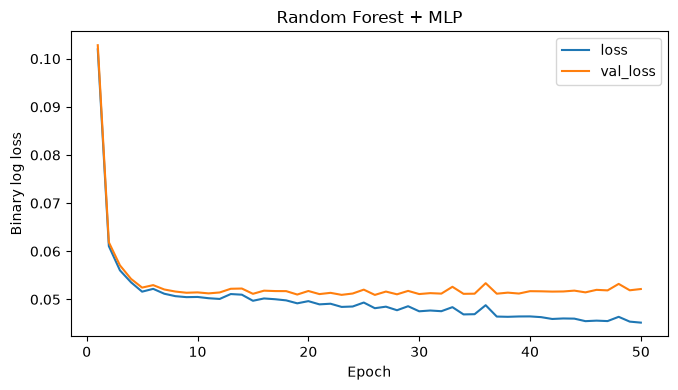

Epoch   1/50  loss=0.10194  val_loss=0.10281
Epoch   2/50  loss=0.06106  val_loss=0.06187
Epoch   3/50  loss=0.05604  val_loss=0.05708
Epoch   4/50  loss=0.05355  val_loss=0.05426
Epoch   5/50  loss=0.05161  val_loss=0.05245
Epoch   6/50  loss=0.05219  val_loss=0.05297
Epoch   7/50  loss=0.05118  val_loss=0.05206
Epoch   8/50  loss=0.05067  val_loss=0.05163
Epoch   9/50  loss=0.05047  val_loss=0.05138
Epoch  10/50  loss=0.05051  val_loss=0.05146
Epoch  11/50  loss=0.05024  val_loss=0.05125
Epoch  12/50  loss=0.05009  val_loss=0.05144
Epoch  13/50  loss=0.05111  val_loss=0.05221
Epoch  14/50  loss=0.05098  val_loss=0.05226
Epoch  15/50  loss=0.04971  val_loss=0.05116
Epoch  16/50  loss=0.05020  val_loss=0.05181
Epoch  17/50  loss=0.05004  val_loss=0.05173
Epoch  18/50  loss=0.04980  val_loss=0.05172
Epoch  19/50  loss=0.04918  val_loss=0.05101
Epoch  20/50  loss=0.04964  val_loss=0.05175
Epoch  21/50  loss=0.04897  val_loss=0.05110
Epoch  22/50  loss=0.04910  val_loss=0.05136
Epoch  23/

In [26]:
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import log_loss

# Giữ 20% của X_head để đo val_loss. Mỗi giao dịch chỉ cần đi qua rừng một lần.
X_head_train, X_head_val, y_head_train, y_head_val = train_test_split(
    X_head, y_head, test_size=0.2, stratify=y_head, random_state=42
)
tree_features = FunctionTransformer(tree_fraud_probabilities, kw_args={'forest': hybrid_forest})
Z_train = tree_features.fit_transform(X_head_train)
Z_val = tree_features.transform(X_head_val)

head = MLPClassifier(
    hidden_layer_sizes=(64,), activation='relu', batch_size=512,
    random_state=np.random.RandomState(42),
)
epochs = 50
train_losses, val_losses = [], []
fig, ax = plt.subplots(figsize=(7, 4))
train_line, = ax.plot([], [], label='loss')
val_line, = ax.plot([], [], label='val_loss')
ax.set(xlabel='Epoch', ylabel='Binary log loss', title='Random Forest + MLP')
ax.legend()
fig.tight_layout()
chart = display(fig, display_id=True)
plt.close(fig)

for epoch in range(1, epochs + 1):
    # partial_fit chạy một epoch và giữ trạng thái Adam cho epoch tiếp theo.
    head.partial_fit(Z_train, y_head_train, classes=hybrid_forest.classes_)
    train_losses.append(log_loss(y_head_train, head.predict_proba(Z_train), labels=head.classes_))
    val_losses.append(log_loss(y_head_val, head.predict_proba(Z_val), labels=head.classes_))
    print(f'Epoch {epoch:3d}/{epochs}  loss={train_losses[-1]:.5f}  val_loss={val_losses[-1]:.5f}', flush=True)

    train_line.set_data(range(1, epoch + 1), train_losses)
    val_line.set_data(range(1, epoch + 1), val_losses)
    ax.relim()
    ax.autoscale_view()
    chart.update(fig)

rf_mlp_model = make_pipeline(tree_features, head)

## 2.3: GLM-offset boosting

In [27]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

glm_model = LogisticRegression(solver='newton-cholesky', max_iter=100)
glm_model.fit(X_train_selected, y_train)

# Offset là log-odds của từng giao dịch trước khi boosting.
glm_offset_model = XGBClassifier(
    objective='binary:logistic',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    n_jobs=2,
)
glm_offset_model.fit(
    X_train_selected, y_train,
    base_margin=glm_model.decision_function(X_train_selected),
)

def predict_glm_offset_proba(features):
    offset = glm_model.decision_function(features)
    fraud_index = list(glm_offset_model.classes_).index(1)
    return glm_offset_model.predict_proba(features, base_margin=offset)[:, fraud_index]

## 2.4: RealMLP

In [28]:
import numpy as np
from pytabkit import RealMLP_TD_Classifier
from sklearn.model_selection import train_test_split

# val_idxs là vị trí dòng trong X_train_selected. Chia phân tầng để giữ tỷ lệ gian lận.
_, real_mlp_val_idxs = train_test_split(
    np.arange(len(y_train)), test_size=0.15, stratify=y_train, random_state=42
)

real_mlp_model = RealMLP_TD_Classifier(
    random_state=42,
    hidden_sizes=[128, 128, 64],
    batch_size=1024,
    n_epochs=32,
    n_threads=4,
    val_metric_name='cross_entropy',
    use_ls=False,
    use_early_stopping=True,
    early_stopping_additive_patience=6,
    early_stopping_multiplicative_patience=1,
    verbosity=2,
)
real_mlp_model.fit(X_train_selected, y_train, val_idxs=real_mlp_val_idxs)

d:\ML_Project\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Columns classified as continuous: ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'ip_country_mismatch', 'is_foreign_transaction', 'billing_shipping_mismatch', 'is_new_merchant', 'used_vpn', 'is_ai_generated_scam_attempt', 'merchant_category', 'auth_method', 'device_type', 'channel', 'card_type']
Columns classified as categorical: []


d:\ML_Project\.venv\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Epoch 1/32: val cross_entropy = 0.062367
Epoch 2/32: val cross_entropy = 0.050711
Epoch 3/32: val cross_entropy = 0.052676
Epoch 4/32: val cross_entropy = 0.050022
Epoch 5/32: val cross_entropy = 0.049269
Epoch 6/32: val cross_entropy = 0.048049
Epoch 7/32: val cross_entropy = 0.048184
Epoch 8/32: val cross_entropy = 0.049178
Epoch 9/32: val cross_entropy = 0.050428
Epoch 10/32: val cross_entropy = 0.049112
Epoch 11/32: val cross_entropy = 0.050792
Epoch 12/32: val cross_entropy = 0.048849
Epoch 13/32: val cross_entropy = 0.048161


,random_state,42
,n_threads,4
,verbosity,2
,val_metric_name,'cross_entropy'
,n_epochs,32
,batch_size,1024
,hidden_sizes,"[128, 128, ...]"
,use_ls,False
,use_early_stopping,True
,early_stopping_additive_patience,6
,early_stopping_multiplicative_patience,1


# 3: Evaluate

## 3.1: Traditonal ML

### Decison Tree

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

# X_test la tap validation duoc tach tu train.csv
y_pred = tree_model.predict(X_test_selected)
y_proba = tree_model.predict_proba(X_test_selected)[:, 1]

print('Average Precision:', round(average_precision_score(y_test, y_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
print('Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):')
print(confusion_matrix(y_test, y_pred))

Average Precision: 0.1893
ROC-AUC: 0.8886
              precision    recall  f1-score   support

           0     0.9955    0.8622    0.9240    137654
           1     0.0866    0.7699    0.1558      2338

    accuracy                         0.8606    139992
   macro avg     0.5411    0.8160    0.5399    139992
weighted avg     0.9803    0.8606    0.9112    139992

Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):
[[118680  18974]
 [   538   1800]]


#Save submission

In [ ]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(tree_model.classes_).index(1)
fraud_probabilities = tree_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/dtree_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()


Đã lưu 299,984 dòng vào D:\ML_Project\submissions\dtree_submission.csv


,id,is_fraud
0,699960,0.181301
1,699961,0.048500
2,699962,0.670203
3,699963,0.048500
4,699964,0.181301


### Random Forest

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score


y_pred = rf_model.predict(X_test_selected)
y_proba = rf_model.predict_proba(X_test_selected)[:, 1]

print('Average Precision:', round(average_precision_score(y_test, y_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
print('Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):')
print(confusion_matrix(y_test, y_pred))

Average Precision: 0.4417
ROC-AUC: 0.9271
              precision    recall  f1-score   support

           0     0.9912    0.9879    0.9896    137654
           1     0.4051    0.4855    0.4416      2338

    accuracy                         0.9795    139992
   macro avg     0.6981    0.7367    0.7156    139992
weighted avg     0.9814    0.9795    0.9804    139992

Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):
[[135987   1667]
 [  1203   1135]]


#Save submission

In [ ]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(rf_model.classes_).index(1)
fraud_probabilities = rf_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/rf_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()


Đã lưu 299,984 dòng vào D:\ML_Project\submissions\rf_submission.csv


,id,is_fraud
0,699960,0.022569
1,699961,0.017666
2,699962,0.348430
3,699963,0.026189
4,699964,0.039120


### XGboost

In [29]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score


y_pred = xgb_model.predict(X_test_selected)
y_proba = xgb_model.predict_proba(X_test_selected)[:, 1]

print('Average Precision:', round(average_precision_score(y_test, y_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
print('Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):')
print(confusion_matrix(y_test, y_pred))

Average Precision: 0.5065
ROC-AUC: 0.9443
              precision    recall  f1-score   support

           0     0.9934    0.9780    0.9857    137654
           1     0.3230    0.6176    0.4242      2338

    accuracy                         0.9720    139992
   macro avg     0.6582    0.7978    0.7049    139992
weighted avg     0.9822    0.9720    0.9763    139992

Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):
[[134628   3026]
 [   894   1444]]


#Save submission

In [30]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(xgb_model.classes_).index(1)
fraud_probabilities = xgb_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/xgb_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()


Đã lưu 299,984 dòng vào D:\ML_Project\submissions\xgb_submission.csv


,id,is_fraud
0,699960,0.001685
1,699961,0.001689
2,699962,0.481311
3,699963,0.011640
4,699964,0.016402


## 3.2: MLP

### Simple 2 layer MLP

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

mlp_fraud_index = list(mlp_model.classes_).index(1)
y_pred = mlp_model.predict(X_test_selected)
y_proba = mlp_model.predict_proba(X_test_selected)[:, mlp_fraud_index]

print('Average Precision:', round(average_precision_score(y_test, y_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
print('Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):')
print(confusion_matrix(y_test, y_pred))

Average Precision: 0.4771
ROC-AUC: 0.9337
              precision    recall  f1-score   support

           0     0.9872    0.9991    0.9931    137654
           1     0.8150    0.2374    0.3677      2338

    accuracy                         0.9864    139992
   macro avg     0.9011    0.6182    0.6804    139992
weighted avg     0.9843    0.9864    0.9827    139992

Confusion matrix (hang: thuc te, cot: du doan; thu tu lop: 0, 1):
[[137528    126]
 [  1783    555]]


#Save submission

In [ ]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(mlp_model.classes_).index(1)
fraud_probabilities = mlp_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/mlp_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()

KeyboardInterrupt: 

### Random Forest + MLP

In [38]:
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, roc_auc_score

fraud_index = list(rf_mlp_model.classes_).index(1)
rf_mlp_proba = rf_mlp_model.predict_proba(X_test_selected)[:, fraud_index]
rf_mlp_pred = (rf_mlp_proba >= 0.5).astype(int)

print('Average Precision:', round(average_precision_score(y_test, rf_mlp_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, rf_mlp_proba), 4))
print(classification_report(y_test, rf_mlp_pred, digits=4, zero_division=0))
print(confusion_matrix(y_test, rf_mlp_pred, labels=[0, 1]))

Average Precision: 0.4329
ROC-AUC: 0.928
              precision    recall  f1-score   support

           0     0.9870    0.9986    0.9928    137654
           1     0.7356    0.2237    0.3431      2338

    accuracy                         0.9857    139992
   macro avg     0.8613    0.6112    0.6679    139992
weighted avg     0.9828    0.9857    0.9819    139992

[[137466    188]
 [  1815    523]]


#Save submission

In [39]:
print(rf_mlp_model.classes_)

[0 1]


In [33]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(rf_mlp_model.classes_).index(1)
fraud_probabilities = rf_mlp_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/rf_mlp_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()

Đã lưu 299,984 dòng vào D:\ML_Project\submissions\rf_mlp_submission.csv


,id,is_fraud
0,699960,0.000611
1,699961,0.000453
2,699962,0.078924
3,699963,0.000850
4,699964,0.001890


### RealMLP

In [40]:
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, roc_auc_score

fraud_index = list(real_mlp_model.classes_).index(1)
real_mlp_proba = real_mlp_model.predict_proba(X_test_selected)[:, fraud_index]
real_mlp_pred = (real_mlp_proba >= 0.5).astype(int)

print('Average Precision:', round(average_precision_score(y_test, real_mlp_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, real_mlp_proba), 4))
print(classification_report(y_test, real_mlp_pred, digits=4, zero_division=0))
print(confusion_matrix(y_test, real_mlp_pred, labels=[0, 1]))

d:\ML_Project\.venv\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Average Precision: 0.4995
ROC-AUC: 0.9404
              precision    recall  f1-score   support

           0     0.9883    0.9984    0.9933    137654
           1     0.7621    0.3041    0.4347      2338

    accuracy                         0.9868    139992
   macro avg     0.8752    0.6512    0.7140    139992
weighted avg     0.9845    0.9868    0.9840    139992

[[137432    222]
 [  1627    711]]


In [35]:
from pathlib import Path
import numpy as np

# Dùng preprocessor và model đã fit ở các cell phía trên.
test_data = pd.read_csv('data/test.csv')
submission = pd.read_csv('data/sample_submission.csv')

X_submission = test_data.loc[:, preprocessor.feature_names_in_].copy()
X_submission_encoded = preprocessor.transform(X_submission)
fraud_class_index = list(real_mlp_model.classes_).index(1)
fraud_probabilities = real_mlp_model.predict_proba(X_submission_encoded.loc[:, selected_cols])[:, fraud_class_index]

assert np.isfinite(fraud_probabilities).all(), 'Xác suất chứa NaN hoặc inf'
assert ((fraud_probabilities >= 0) & (fraud_probabilities <= 1)).all()
assert test_data['id'].is_unique and submission['id'].is_unique
assert len(submission) == len(test_data)
assert set(submission['id']) == set(test_data['id']), 'ID không khớp mẫu submission'

probabilities_by_id = pd.Series(fraud_probabilities, index=test_data['id'])
submission['is_fraud'] = submission['id'].map(probabilities_by_id)
assert submission['is_fraud'].notna().all()

output_path = Path('submissions/real_mlp_submission.csv')
submission.to_csv(output_path, index=False)
print(f'Đã lưu {len(submission):,} dòng vào {output_path.resolve()}')
submission.head()

d:\ML_Project\.venv\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Đã lưu 299,984 dòng vào D:\ML_Project\submissions\real_mlp_submission.csv


,id,is_fraud
0,699960,0.000246
1,699961,0.000135
2,699962,0.092319
3,699963,0.000795
4,699964,0.002312


## 3.3: GLM-offset boosting

In [41]:
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, roc_auc_score

glm_offset_proba = predict_glm_offset_proba(X_test_selected)
glm_offset_pred = (glm_offset_proba >= 0.5).astype(int)

print('Average Precision:', round(average_precision_score(y_test, glm_offset_proba), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, glm_offset_proba), 4))
print(classification_report(y_test, glm_offset_pred, digits=4, zero_division=0))
print('Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán; thứ tự lớp: 0, 1)')
print(confusion_matrix(y_test, glm_offset_pred, labels=[0, 1]))

Average Precision: 0.5186
ROC-AUC: 0.9459
              precision    recall  f1-score   support

           0     0.9884    0.9985    0.9934    137654
           1     0.7805    0.3088    0.4425      2338

    accuracy                         0.9870    139992
   macro avg     0.8845    0.6537    0.7180    139992
weighted avg     0.9849    0.9870    0.9842    139992

Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán; thứ tự lớp: 0, 1)
[[137451    203]
 [  1616    722]]


#Save submission

In [37]:
from pathlib import Path

glm_test_data = pd.read_csv('data/test.csv')
glm_submission = pd.read_csv('data/sample_submission.csv')
glm_test_encoded = preprocessor.transform(glm_test_data.loc[:, preprocessor.feature_names_in_])
glm_test_proba = predict_glm_offset_proba(glm_test_encoded.loc[:, selected_cols])

assert glm_test_data['id'].is_unique and glm_submission['id'].is_unique
assert len(glm_test_data) == len(glm_submission)

glm_proba_by_id = pd.Series(glm_test_proba, index=glm_test_data['id'])
glm_submission['is_fraud'] = glm_submission['id'].map(glm_proba_by_id)
assert glm_submission['is_fraud'].between(0, 1).all()

glm_output_path = Path('submissions/glm_offset_boosting_submission.csv')
glm_output_path.parent.mkdir(exist_ok=True)
glm_submission.to_csv(glm_output_path, index=False)
print(f'Đã lưu {len(glm_submission):,} dòng vào {glm_output_path}')
submission.head()

Đã lưu 299,984 dòng vào submissions\glm_offset_boosting_submission.csv


,id,is_fraud
0,699960,0.000246
1,699961,0.000135
2,699962,0.092319
3,699963,0.000795
4,699964,0.002312


# 4: Tổng hợp kết quả của các thử nghiệm



## 4.1. Dữ liệu và cách đánh giá

Tập `train.csv` có 699.960 giao dịch, trong đó 11.689 giao dịch là gian lận (1,67%). Nếu luôn dự đoán giao dịch hợp lệ, accuracy đã đạt 98,33% dù bỏ sót toàn bộ gian lận. Vì vậy, báo cáo dùng Average Precision (AP) và ROC-AUC để đánh giá khả năng xếp hạng rủi ro, đồng thời dùng precision, recall và F1 của lớp gian lận để đánh giá các cảnh báo ở ngưỡng 0,5.

- **Làm sạch và khám phá.** Dữ liệu huấn luyện không có giá trị thiếu. Cột `id` được loại khỏi đầu vào và dùng để ghép kết quả khi xuất submission. Sau khi so sánh tỷ lệ gian lận theo nhóm, notebook giữ `merchant_category` và `auth_method`, loại `card_type`, `channel` và `device_type` vì tỷ lệ giữa các nhóm ít khác biệt. Các biến số được khảo sát bằng boxplot và tương quan Pearson, sau đó giữ nguyên giá trị.
- **Chia tập và mã hóa.** Chia phân tầng theo `is_fraud` với `random_state=42`, thu được 559.968 giao dịch để huấn luyện và 139.992 giao dịch để đánh giá nội bộ, gồm 2.338 ca gian lận. Bộ mã hóa được khớp trên phần huấn luyện. Hai biến phân loại được mã hóa one-hot, các biến Boolean chuyển thành 0/1.
- **Chọn đặc trưng.** Trên phần huấn luyện, kiểm định χ² xếp hạng 23 cột one-hot và Boolean. Giữ 12 cột điểm cao nhất cùng toàn bộ 13 cột số, thu được **25 đặc trưng**. Ba cột đứng đầu theo χ² là `ip_country_mismatch`, `auth_method_No Authentication` và `is_foreign_transaction`.
- **Xuất dự đoán.** Cùng bộ tiền xử lý và danh sách đặc trưng được áp dụng cho 299.984 giao dịch trong `test.csv`. Mỗi submission chứa xác suất `is_fraud = 1`, ghép theo `id` vào thứ tự của file mẫu.

## 4.2. Sáu phương pháp huấn luyện

| Phương pháp | Cách huấn luyện trong notebook |
|---|---|
| Decision Tree | Một cây sâu tối đa 8 tầng, tối đa 50 nút lá, chọn điểm chia ngẫu nhiên. Trọng số lớp `balanced` làm tăng ảnh hưởng của các ca gian lận khi chọn điểm chia. |
| Random Forest | Lấy trung bình xác suất của 100 cây. Mỗi cây sâu tối đa 8 tầng, mỗi lá có ít nhất 50 mẫu. Trọng số của lớp gian lận gấp 10 lần lớp hợp lệ. |
| XGBoost | Huấn luyện tuần tự 300 cây sâu tối đa 5 tầng, tốc độ học 0,05. Mỗi vòng lấy mẫu 80% số dòng và 80% số cột. Đặt `scale_pos_weight=10` cho lớp gian lận. |
| MLP | Đưa trực tiếp 25 đặc trưng vào hai lớp ẩn ReLU gồm 64 và 32 neuron, sau đó qua đầu ra sigmoid. Dùng Adam, batch 512, tối đa 100 epoch. |
| Random Forest + MLP | Mỗi cây trả về một xác suất gian lận. Vector 100 xác suất đi qua một lớp ẩn ReLU 64 neuron rồi qua sigmoid. Trong 80% dữ liệu dành cho huấn luyện, rừng học trên 75%, MLP học trên 20% và 5% còn lại dùng để theo dõi `val_loss`. Cấu hình đang lưu chạy 50 epoch. |
| GLM-offset boosting | Hồi quy logistic ước lượng log-odds ban đầu cho từng giao dịch. XGBoost dùng giá trị này làm `base_margin`, rồi học phần hiệu chỉnh qua 300 cây sâu tối đa 5 tầng với tốc độ học 0,05. Khi dự đoán, mô hình tính lại offset cho từng giao dịch mới. |

**Diễn biến huấn luyện của Random Forest + MLP.** Ở epoch 1, log loss trên tập học của MLP là 0,10182 và trên tập validation riêng là 0,10233. Validation loss thấp nhất được ghi nhận tại epoch 34 (0,04988). Đến epoch 50, loss tập học tiếp tục giảm còn 0,04525, trong khi validation loss tăng nhẹ lên 0,05035. Kết quả ở mục 3 dùng trọng số epoch 50.

## 4.3. Hiệu năng trên tập đánh giá nội bộ

Các số dưới đây lấy từ mục 3, trên cùng 139.992 giao dịch giữ lại từ `train.csv`. AP và ROC-AUC được tính từ xác suất dự đoán. Ba cột cuối chỉ tính cho lớp gian lận ở ngưỡng mặc định 0,5.

| Phương pháp | AP | ROC-AUC | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|
| Decision Tree | 0,1893 | 0,8886 | 0,0866 | **0,7699** | 0,1558 |
| Random Forest | 0,4417 | 0,9271 | 0,4051 | 0,4855 | 0,4416 |
| XGBoost | 0,5012 | 0,9429 | 0,3148 | 0,6202 | 0,4176 |
| MLP | 0,4771 | 0,9337 | **0,8150** | 0,2374 | 0,3677 |
| Random Forest + MLP | 0,4526 | 0,9317 | 0,7141 | 0,2746 | 0,3967 |
| GLM-offset boosting | **0,5152** | **0,9449** | 0,7802 | 0,3174 | **0,4512** |

Decision Tree phát hiện được nhiều ca gian lận nhất (1.800/2.338), nhưng cũng tạo 18.974 cảnh báo nhầm. MLP có precision cao nhất, với 555 ca gian lận trong 681 cảnh báo, song bỏ sót 1.783 ca. GLM-offset boosting đạt AP, ROC-AUC và F1 cao nhất trong sáu phương pháp. Ở ngưỡng 0,5, mô hình này phát hiện 742 ca và báo nhầm 209 ca.

Việc thay phép lấy trung bình của rừng bằng MLP đi kèm một đánh đổi trong hai cấu hình đã chạy. AP tăng từ 0,4417 lên 0,4526 và precision tăng từ 0,4051 lên 0,7141, trong khi recall giảm từ 0,4855 xuống 0,2746. Hai cấu hình cũng dùng lượng dữ liệu khác nhau để huấn luyện rừng, nên không thể quy toàn bộ chênh lệch cho riêng lớp MLP.

## 4.4. Kết quả submission thực tế

Bảng ghi lại đủ bảy lượt nộp trong ảnh, sắp theo điểm từ cao xuống thấp. Ảnh chỉ hiển thị điểm, không hiển thị tên chỉ số chấm. Hai lượt nộp của Random Forest + MLP trùng tên file nên được phân biệt theo thứ tự thời gian.

| Phương pháp | File đã nộp | Điểm submission |
|---|---|---:|
| GLM-offset boosting | `glm_offset_boosting_submission.csv` | **0,94713** |
| XGBoost | `xgb_submission.csv` | 0,94441 |
| MLP | `mlp_submission.csv` | 0,93668 |
| Random Forest + MLP | `rf_mlp_submission.csv` | 0,93539 |
| Random Forest | `rf_submission.csv` | 0,92932 |
| Decision Tree | `submission.csv` | 0,89428 |

**GLM-offset boosting đứng đầu cả về AP nội bộ (0,5152) và điểm nộp thực tế (0,94713)**, cao hơn XGBoost 0,00272 điểm submission. Nếu lấy lượt nộp tốt nhất của mỗi phương pháp, thứ tự sáu mô hình trên bảng điểm cũng trùng với thứ tự theo ROC-AUC nội bộ. Riêng Random Forest + MLP tăng 0,12309 điểm giữa hai lượt nộp. Ảnh không ghi cấu hình từng lượt nên chưa đủ căn cứ để xác định thay đổi nào tạo ra mức tăng này.